Real reference images: 1500
GAN generated images: 38
Diffusion generated images: 17


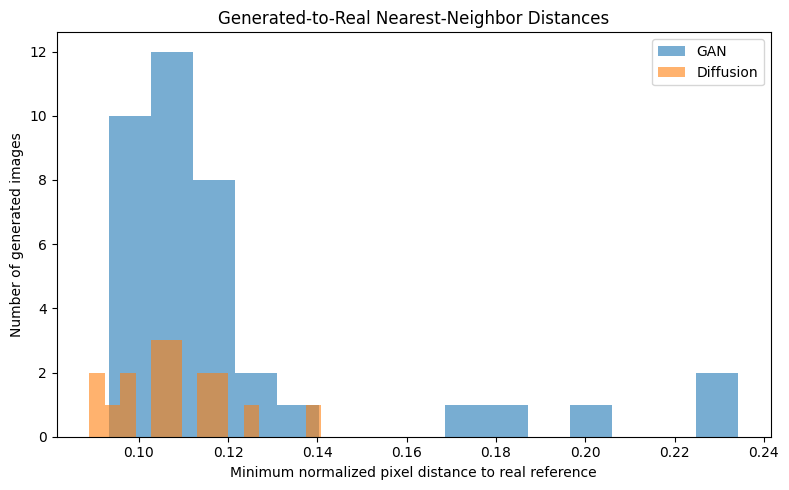

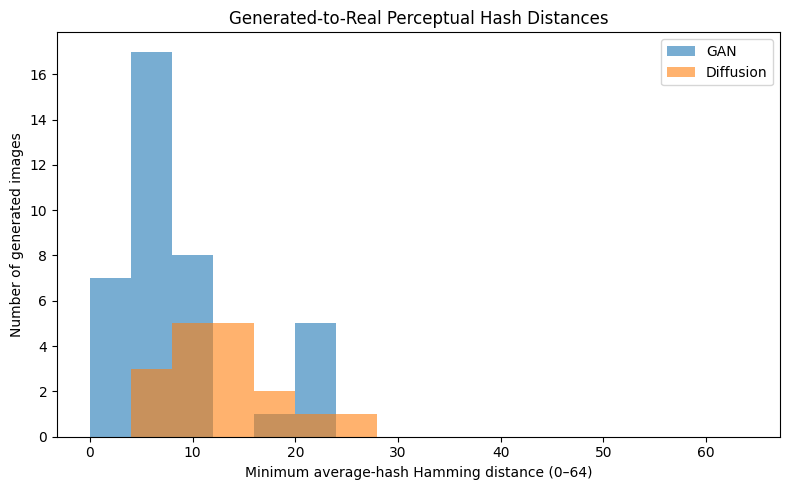

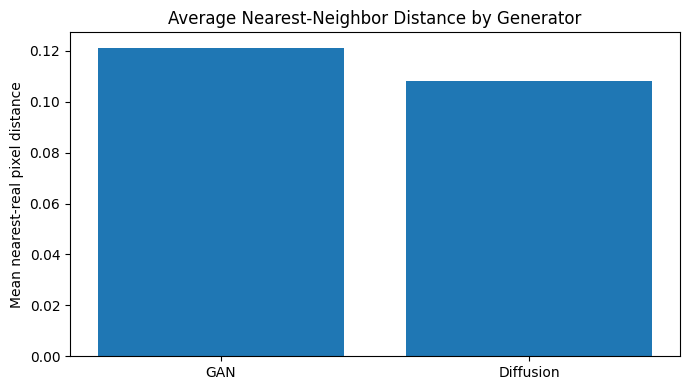


NOTEBOOK 13 COMPLETED
Output folder: /kaggle/working/nd_iris_project/notebook13_privacy_leakage
ZIP: /kaggle/working/nd_iris_project/ND_Iris_Notebook13_Results.zip
ZIP files: 9
ZIP integrity: PASSED
Conclusion file: /kaggle/working/nd_iris_project/notebook13_privacy_leakage/Notebook13_Conclusion.md
Runtime seconds: 38.7

REAL DATASET DUPLICATE SUMMARY


,real_images_evaluated,exact_duplicate_groups,exact_duplicate_excess_images,mean_nearest_real_pixel_distance,median_nearest_real_pixel_distance,mean_nearest_real_phash_hamming
0,1500,2,2,0.0727,0.075085,2.936



GENERATED-TO-REAL SIMILARITY SUMMARY


,group,n_images,exact_matches,mean_nearest_pixel_distance,median_nearest_pixel_distance,mean_nearest_phash_hamming,low_distance_threshold,low_distance_count
0,GAN,38,0,0.12123,0.11111,8.02632,0.05,0
1,Diffusion,17,0,0.10807,0.10880,12.58824,0.05,0



Generated images compared: 55
Evaluation errors: 0


In [18]:

# ============================================================
# NOTEBOOK 13: PRIVACY LEAKAGE ANALYSIS
# Dataset: NDCLD15 / ND-Iris
# ============================================================

from pathlib import Path
from PIL import Image, ImageOps
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import hashlib, json, random, time, zipfile

# -------------------- CONFIGURATION --------------------------
PROJECT = Path("/kaggle/working/nd_iris_project")

REAL_DIR = PROJECT / "notebook02_preprocessing/images_224"
GAN_DIR = PROJECT / "notebook06_gan_augmentation/generated_samples"
DIFF_DIR = PROJECT / "notebook07_diffusion_training/generated_samples"

OUT = PROJECT / "notebook13_privacy_leakage"
OUT.mkdir(parents=True, exist_ok=True)

SEED = 42
MAX_REAL = 1500
MAX_GENERATED_EACH = 100
IMAGE_SIZE = (64, 64)

random.seed(SEED)
np.random.seed(SEED)
start_time = time.time()

EXTS = {".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp"}

def discover_images(folder):
    if not folder.exists():
        return []
    return sorted(
        p for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in EXTS
    )

real_files = discover_images(REAL_DIR)
gan_files = discover_images(GAN_DIR)
diff_files = discover_images(DIFF_DIR)

if not real_files:
    raise FileNotFoundError(f"No real images found: {REAL_DIR}")

rng = random.Random(SEED)
if len(real_files) > MAX_REAL:
    real_files = sorted(rng.sample(real_files, MAX_REAL))
gan_files = gan_files[:MAX_GENERATED_EACH]
diff_files = diff_files[:MAX_GENERATED_EACH]

print("Real reference images:", len(real_files))
print("GAN generated images:", len(gan_files))
print("Diffusion generated images:", len(diff_files))

# -------------------- LOAD / NORMALIZE ------------------------
def load_image(path):
    with Image.open(path) as im:
        im = ImageOps.grayscale(im)
        im = ImageOps.fit(im, IMAGE_SIZE)
        return np.asarray(im, dtype=np.uint8)

def exact_hash(arr):
    return hashlib.sha256(arr.tobytes()).hexdigest()

def normalized_pixel_distance(a, b):
    return float(np.mean(
        np.abs(a.astype(np.float32) - b.astype(np.float32))
    ) / 255.0)

def perceptual_hash(path):
    # Simple average hash; useful for screening only.
    with Image.open(path) as im:
        im = ImageOps.grayscale(im).resize((8, 8))
        arr = np.asarray(im, dtype=np.float32)
    return arr > arr.mean()

def hamming_distance(a, b):
    return int(np.count_nonzero(a != b))

# -------------------- LOAD REAL REFERENCE SET -----------------
real_arrays = []
real_hashes = []
real_phashes = []
real_paths = []
errors = []

for p in real_files:
    try:
        arr = load_image(p)
        real_arrays.append(arr)
        real_hashes.append(exact_hash(arr))
        real_phashes.append(perceptual_hash(p))
        real_paths.append(str(p))
    except Exception as e:
        errors.append({"path": str(p), "error": str(e)})

if len(real_arrays) < 2:
    raise RuntimeError("Not enough valid real images for comparison.")

real_arrays = np.stack(real_arrays)
real_phashes = np.stack(real_phashes)
real_hash_set = set(real_hashes)

# -------------------- REAL-REAL DUPLICATE SCREENING -----------
# Exact duplicates after resizing/grayscale normalization.
hash_counts = pd.Series(real_hashes).value_counts()
exact_duplicate_groups = int((hash_counts > 1).sum())
exact_duplicate_excess = int((hash_counts[hash_counts > 1] - 1).sum())

# Sampled real-real nearest-neighbor distances.
# Each image is compared to the reference set; self-match excluded.
nearest_real_distances = []
nearest_real_phash = []

for i, arr in enumerate(real_arrays):
    candidates = np.arange(len(real_arrays)) != i
    other = real_arrays[candidates]
    if len(other) == 0:
        continue

    distances = np.mean(
        np.abs(other.astype(np.float32) - arr.astype(np.float32)),
        axis=(1, 2)
    ) / 255.0
    nearest_real_distances.append(float(distances.min()))

    p_other = real_phashes[candidates]
    hd = np.count_nonzero(p_other != real_phashes[i], axis=(1, 2))
    nearest_real_phash.append(int(hd.min()))

# -------------------- GENERATED-TO-REAL COMPARISON ------------
def compare_generated(files, group_name):
    rows = []

    for p in files:
        try:
            arr = load_image(p)
            ph = perceptual_hash(p)
            h = exact_hash(arr)

            distances = np.mean(
                np.abs(real_arrays.astype(np.float32) - arr.astype(np.float32)),
                axis=(1, 2)
            ) / 255.0

            nearest_idx = int(np.argmin(distances))
            min_pixel_distance = float(distances[nearest_idx])
            min_phash_distance = int(
                np.count_nonzero(real_phashes != ph, axis=(1, 2)).min()
            )

            rows.append({
                "generated_group": group_name,
                "generated_filename": p.name,
                "exact_hash_match_to_real": h in real_hash_set,
                "nearest_real_pixel_distance": min_pixel_distance,
                "nearest_real_phash_hamming": min_phash_distance,
                "nearest_real_filename": Path(real_paths[nearest_idx]).name
            })
        except Exception as e:
            errors.append({"path": str(p), "error": str(e)})

    return rows

generated_rows = []
generated_rows.extend(compare_generated(gan_files, "GAN"))
generated_rows.extend(compare_generated(diff_files, "Diffusion"))

gen_df = pd.DataFrame(generated_rows)
gen_csv = OUT / "generated_to_real_similarity.csv"
gen_df.to_csv(gen_csv, index=False)

# -------------------- SUMMARY --------------------------------
summary = []

for group in ["GAN", "Diffusion"]:
    subset = gen_df[gen_df["generated_group"] == group]
    if subset.empty:
        summary.append({
            "group": group, "n_images": 0,
            "exact_matches": 0,
            "mean_nearest_pixel_distance": None,
            "median_nearest_pixel_distance": None,
            "mean_nearest_phash_hamming": None,
            "low_distance_count": 0
        })
        continue

    # Threshold is only a heuristic screening threshold.
    # It is not a validated privacy-leakage threshold.
    low_distance_threshold = 0.05

    summary.append({
        "group": group,
        "n_images": len(subset),
        "exact_matches": int(subset["exact_hash_match_to_real"].sum()),
        "mean_nearest_pixel_distance": float(
            subset["nearest_real_pixel_distance"].mean()
        ),
        "median_nearest_pixel_distance": float(
            subset["nearest_real_pixel_distance"].median()
        ),
        "mean_nearest_phash_hamming": float(
            subset["nearest_real_phash_hamming"].mean()
        ),
        "low_distance_threshold": low_distance_threshold,
        "low_distance_count": int(
            (subset["nearest_real_pixel_distance"] <= low_distance_threshold).sum()
        )
    })

summary_df = pd.DataFrame(summary)
summary_df.to_csv(OUT / "privacy_similarity_summary.csv", index=False)

real_summary = {
    "real_images_evaluated": int(len(real_arrays)),
    "exact_duplicate_groups": exact_duplicate_groups,
    "exact_duplicate_excess_images": exact_duplicate_excess,
    "mean_nearest_real_pixel_distance": (
        float(np.mean(nearest_real_distances))
        if nearest_real_distances else None
    ),
    "median_nearest_real_pixel_distance": (
        float(np.median(nearest_real_distances))
        if nearest_real_distances else None
    ),
    "mean_nearest_real_phash_hamming": (
        float(np.mean(nearest_real_phash))
        if nearest_real_phash else None
    )
}

with open(OUT / "real_dataset_duplicate_summary.json", "w") as f:
    json.dump(real_summary, f, indent=2)

# -------------------- PLOTS ----------------------------------
plot_paths = []

# Nearest pixel-distance distributions
fig, ax = plt.subplots(figsize=(8, 5))
for group in ["GAN", "Diffusion"]:
    subset = gen_df[gen_df["generated_group"] == group]
    if len(subset):
        ax.hist(
            subset["nearest_real_pixel_distance"],
            bins=15, alpha=0.6, label=group
        )

ax.set_xlabel("Minimum normalized pixel distance to real reference")
ax.set_ylabel("Number of generated images")
ax.set_title("Generated-to-Real Nearest-Neighbor Distances")
ax.legend()
fig.tight_layout()
p = OUT / "nearest_pixel_distance_distribution.png"
fig.savefig(p, dpi=150)
plt.show()
plt.close(fig)
plot_paths.append(p)

# Perceptual hash distance distribution
fig, ax = plt.subplots(figsize=(8, 5))
for group in ["GAN", "Diffusion"]:
    subset = gen_df[gen_df["generated_group"] == group]
    if len(subset):
        ax.hist(
            subset["nearest_real_phash_hamming"],
            bins=range(0, 66, 4), alpha=0.6, label=group
        )

ax.set_xlabel("Minimum average-hash Hamming distance (0–64)")
ax.set_ylabel("Number of generated images")
ax.set_title("Generated-to-Real Perceptual Hash Distances")
ax.legend()
fig.tight_layout()
p = OUT / "nearest_phash_distance_distribution.png"
fig.savefig(p, dpi=150)
plt.show()
plt.close(fig)
plot_paths.append(p)

# Summary bar plot
fig, ax = plt.subplots(figsize=(7, 4))
valid = summary_df.dropna(subset=["mean_nearest_pixel_distance"])
if not valid.empty:
    ax.bar(
        valid["group"],
        valid["mean_nearest_pixel_distance"]
    )
ax.set_ylabel("Mean nearest-real pixel distance")
ax.set_title("Average Nearest-Neighbor Distance by Generator")
fig.tight_layout()
p = OUT / "mean_nearest_pixel_distance.png"
fig.savefig(p, dpi=150)
plt.show()
plt.close(fig)
plot_paths.append(p)

# -------------------- REPORT ---------------------------------
elapsed = round(time.time() - start_time, 2)

report = {
    "notebook": "13 - Privacy Leakage Analysis",
    "dataset": "NDCLD15 / ND-Iris",
    "real_reference_summary": real_summary,
    "generated_summary": summary,
    "generated_images_compared": int(len(gen_df)),
    "loading_or_evaluation_errors": len(errors),
    "runtime_seconds": elapsed,
    "interpretation_cautions": [
        "Nearest-neighbor similarity is a screening signal, not proof of privacy leakage.",
        "Exact matches are evaluated after grayscale conversion and resizing, not on original file bytes.",
        "Average hash and pixel distance are sensitive to image alignment and preprocessing.",
        "No verified subject identity labels or consent metadata are used.",
        "The real reference set is a sample of the available dataset, so nearest matches may be missed.",
        "No membership inference or identity re-identification attack is performed in this notebook."
    ]
}

with open(OUT / "privacy_leakage_report.json", "w") as f:
    json.dump(report, f, indent=2)

pd.DataFrame(errors).to_csv(OUT / "evaluation_errors.csv", index=False)

conclusion_lines = [
    "# Notebook 13 — Privacy Leakage Analysis",
    "",
    "## Objective",
    "Screen generated images for exact normalized matches and nearest-neighbor similarity to a sampled real-image reference set.",
    "",
    "## Real reference-set findings",
    f"- Real images evaluated: {real_summary['real_images_evaluated']}",
    f"- Exact duplicate groups after normalization: {real_summary['exact_duplicate_groups']}",
    f"- Excess images in exact-duplicate groups: {real_summary['exact_duplicate_excess_images']}",
    f"- Mean nearest-real pixel distance within reference set: {real_summary['mean_nearest_real_pixel_distance']}",
    f"- Mean nearest-real average-hash Hamming distance: {real_summary['mean_nearest_real_phash_hamming']}",
    "",
    "## Generated-to-real findings",
    summary_df.to_markdown(index=False),
    "",
    "## Interpretation",
    "Lower nearest-neighbor distances indicate greater low-level similarity under the selected preprocessing. "
    "They do not establish that a generated image reveals a training image or identifies a person.",
    "",
    "## Limitations",
    "- The real reference set is sampled, not the complete dataset.",
    "- Similarity is measured after grayscale conversion and resizing.",
    "- Average hash and pixel distance are simple screening measures, not validated privacy metrics.",
    "- No verified subject identity labels are available.",
    "- No formal re-identification or target-model membership attack is conducted.",
    "",
    "## Conclusion",
    "This notebook provides an exploratory similarity screen for potential memorization signals. "
    "Any close matches should be manually reviewed and evaluated with stronger metrics before drawing privacy conclusions. "
    "Absence of close matches in this sample does not prove privacy safety."
]

(OUT / "Notebook13_Conclusion.md").write_text(
    "\n".join(conclusion_lines), encoding="utf-8"
)

# -------------------- ZIP + VALIDATION ------------------------
zip_path = PROJECT / "ND_Iris_Notebook13_Results.zip"
if zip_path.exists():
    zip_path.unlink()

with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for p in OUT.rglob("*"):
        if p.is_file():
            zf.write(
                p,
                arcname=str(Path("notebook13_privacy_leakage") / p.relative_to(OUT))
            )

with zipfile.ZipFile(zip_path, "r") as zf:
    bad_file = zf.testzip()
    zip_count = len(zf.namelist())

print("\n" + "=" * 60)
print("NOTEBOOK 13 COMPLETED")
print("=" * 60)
print("Output folder:", OUT)
print("ZIP:", zip_path)
print("ZIP files:", zip_count)
print("ZIP integrity:", "PASSED" if bad_file is None else f"FAILED: {bad_file}")
print("Conclusion file:", OUT / "Notebook13_Conclusion.md")
print("Runtime seconds:", elapsed)

print("\nREAL DATASET DUPLICATE SUMMARY")
display(pd.DataFrame([real_summary]))

print("\nGENERATED-TO-REAL SIMILARITY SUMMARY")
display(summary_df.round(5))

print("\nGenerated images compared:", len(gen_df))
print("Evaluation errors:", len(errors))



# Notebook 13 — Privacy Leakage Analysis: Conclusion

## Objective
This notebook screened GAN- and diffusion-generated images for exact normalized matches and nearest-neighbor similarity to a sampled real-image reference set.

## Experimental Results
- Real reference images evaluated: 1,500
- GAN images evaluated: 38
- Diffusion images evaluated: 17
- Total generated images compared: 55
- Evaluation errors: 0
- ZIP integrity: Passed

### Real Dataset Duplicate Screening
- Exact duplicate groups after grayscale conversion and resizing: 2
- Excess images in those groups: 2
- Mean nearest-real pixel distance: 0.0727
- Median nearest-real pixel distance: 0.075085
- Mean nearest-real average-hash Hamming distance: 2.936

### GAN Results
- Exact normalized matches to the real reference set: 0
- Mean nearest-real pixel distance: 0.12123
- Median nearest-real pixel distance: 0.11111
- Mean nearest-real average-hash Hamming distance: 8.02632
- Images below the 0.05 pixel-distance screening threshold: 0

### Diffusion Results
- Exact normalized matches to the real reference set: 0
- Mean nearest-real pixel distance: 0.10807
- Median nearest-real pixel distance: 0.10880
- Mean nearest-real average-hash Hamming distance: 12.58824
- Images below the 0.05 pixel-distance screening threshold: 0

## Interpretation
Neither generator produced an exact normalized match to the sampled real reference set. Diffusion had a lower mean nearest-real pixel distance, whereas GAN had a lower mean perceptual-hash Hamming distance. Since the two similarity measures give different comparisons, neither result establishes that one generator memorizes more or is safer than the other.

Two exact duplicate groups were detected among the sampled real images after normalization. These should be checked against the original files before drawing conclusions about the dataset.

## Limitations
- Only 1,500 real images were included in the reference set.
- Similarity was measured after grayscale conversion and resizing, not by comparing original file bytes.
- Pixel distance and average-hash distance are screening metrics, not validated privacy-risk measures.
- No verified subject identities or identity re-identification tests were used.
- No formal membership-inference attack or proof of training-data memorization was conducted.
- No exact match in this sample does not establish privacy safety.

## Conclusion
This experiment found no exact normalized matches between the evaluated generated images and the sampled real reference set. The nearest-neighbor metrics showed different similarity patterns for GAN and diffusion, so the current evidence is insufficient to rank their privacy risks.

A stronger assessment would require broader reference coverage, review of close matches, and validated privacy or memorization tests. These results should be described as exploratory similarity screening, not proof of privacy protection.
